# ML baseline — Fraud & Collusion Detection in Public Procurement

**Owner:** ML module. **Goal of this notebook:** answer EDA question 6 of the README ("how do the screens relate to the label?") and get a first honest baseline.

Questions it answers:
1. Which pre-computed screens separate `is_cartel = 1` from `0`?
2. How well does a simple model do when validated **by cartel case** (`GroupKFold`)?
3. How much of a random-split score is leakage? (random vs group split)
4. How does it behave on the largest case and on a country it has never seen?

**Run it from the repo root or from `notebooks/`.** Needs: `pip install scikit-learn xgboost matplotlib shap`.

Reminder from the dataset findings: the target is `is_cartel`; PR-AUC of a random model is about 0.42; `cartel_id`, `cartel_tender`, `bidder_id`, `buyer_id` and other IDs are never features.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import GroupKFold, StratifiedKFold, LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, accuracy_score)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42
N_FOLDS = 5
FILENAME = "GTI_labelled_cartel_data_NOV2023.csv"
CANDIDATE_PATHS = [os.path.join("data", "raw", FILENAME), os.path.join("..", "data", "raw", FILENAME)]
DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)
assert DATA_PATH, f"CSV not found. Looked in: {CANDIDATE_PATHS}"
print("Using:", DATA_PATH)

Using: ..\data\raw\GTI_labelled_cartel_data_NOV2023.csv


## 1. Load and sanity checks

In [2]:
df = pd.read_csv(DATA_PATH, low_memory=False)
TARGET, GROUP = "is_cartel", "cartel_id"
y = df[TARGET].astype(int).values
groups = df[GROUP].values

sizes = pd.Series(groups).value_counts()
print("Shape:", df.shape)
print(f"Positive rate: {y.mean():.3f}  -> a random model scores PR-AUC ~ {y.mean():.2f}")
print("Cartel cases:", len(sizes), "| largest case share of rows:", round(sizes.iloc[0] / len(df), 3))

Shape: (15616, 34)
Positive rate: 0.419  -> a random model scores PR-AUC ~ 0.42
Cartel cases: 73 | largest case share of rows: 0.178


## 2. Feature sets

Rules (from the dataset findings): never use the target, `cartel_id`, `cartel_tender` (identifier-like) or raw IDs.
`tender_year` is kept out of the baseline because years can act as a proxy for the cartel period. We test it separately.

In [3]:
BANNED = ["is_cartel", "cartel_id", "cartel_tender", "persistent_id", "tender_id", "lot_id", "bidder_id", "buyer_id"]

numeric_cols = [c for c in df.select_dtypes(include="number").columns if c not in BANNED]
numeric_no_year = [c for c in numeric_cols if c != "tender_year"]

cat = pd.get_dummies(df[["cpv2_smp", "country"]].astype(str), prefix=["cpv2", "country"], dtype=float)

X_sets = {
    "screens": df[numeric_no_year].astype(float),
    "screens + year": df[numeric_cols].astype(float),
    "screens + sector + country": pd.concat([df[numeric_no_year].astype(float), cat], axis=1),
}
for name, X in X_sets.items():
    assert not set(BANNED) & set(X.columns), f"banned column in {name}"
    print(f"{name:30s} {X.shape[1]:3d} features | NaN cells: {int(X.isna().sum().sum())}")
print()
print("Screens used:", numeric_no_year)

screens                         23 features | NaN cells: 0
screens + year                  24 features | NaN cells: 0
screens + sector + country      62 features | NaN cells: 0

Screens used: ['lot_bidscount', 'lot_bidscount_avg', 'lot_bidscount_avg_lag', 'singleb_avg', 'singleb_avg_lag', 'bid_isconsortium', 'bid_issubcontracted', 'bid_issubcontracted_avg', 'bid_issubcontracted_avg_lag', 'relative_value', 'relative_value_avg', 'relative_value_avg_lag', 'cpv3_avg_bidder_yearly', 'cpv3_avg_bidder_yearly_avg_lag', 'buyer_avg_bidder_yearly', 'buyer_avg_bidder_yearly_avg_lag', 'contract_count_bidder_yearly', 'MAD_buyer', 'benfords_buyer_yearly_avg', 'benfords_buyer_yearly_avg_lag', 'MAD_market', 'benfords_market_yearly_avg', 'benfords_market_yearly_avg_lag']


## 3. How does each screen relate to the label?

`strength` = how well one feature alone ranks cartel vs other contracts (0.5 = useless, 1.0 = perfect).
`strength_case_weighted` gives every cartel case the same total weight, so a few huge cases cannot dominate.
If a screen is strong overall but weak case-weighted, it is probably describing a big case, not collusion in general.

In [4]:
case_weight = 1.0 / pd.Series(groups).map(sizes).values
rows = []
for c in X_sets["screens"].columns:
    x = X_sets["screens"][c].values
    if np.nanstd(x) == 0:
        continue
    x = np.nan_to_num(x, nan=np.nanmedian(x))
    auc = roc_auc_score(y, x)
    auc_w = roc_auc_score(y, x, sample_weight=case_weight)
    rows.append({"feature": c, "direction": "+" if auc >= 0.5 else "-",
                 "strength": max(auc, 1 - auc), "strength_case_weighted": max(auc_w, 1 - auc_w),
                 "mean_cartel": x[y == 1].mean(), "mean_other": x[y == 0].mean()})
uni = pd.DataFrame(rows).sort_values("strength", ascending=False).reset_index(drop=True)
display(uni.round(3))

,feature,direction,strength,strength_case_weighted,mean_cartel,mean_other
0,buyer_avg_bidder_yearly,+,0.649,0.519,0.659,0.515
1,benfords_market_yearly_avg,+,0.638,0.576,0.022,0.019
2,bid_issubcontracted_avg,+,0.638,0.535,0.115,0.076
3,cpv3_avg_bidder_yearly_avg_lag,+,0.635,0.507,0.316,0.246
4,lot_bidscount_avg,+,0.630,0.579,8.273,5.458
5,buyer_avg_bidder_yearly_avg_lag,+,0.630,0.503,0.683,0.550
6,contract_count_bidder_yearly,-,0.629,0.517,40.510,110.779
7,cpv3_avg_bidder_yearly,+,0.627,0.514,0.305,0.240
8,bid_issubcontracted_avg_lag,+,0.619,0.545,0.120,0.085
9,lot_bidscount_avg_lag,+,0.608,0.576,10.464,5.760


## 4. Validation helper

Contracts of the same cartel are strongly correlated, so every score below is computed with **`GroupKFold` by `cartel_id`**: a cartel is either entirely in train or entirely in test.
Threshold-free PR-AUC is the main metric; precision/recall/F1 use a fixed 0.5 threshold for now (choosing a threshold properly comes later, on out-of-fold predictions).

In [5]:
def run_cv(make_model, X, y, groups, splitter, threshold=0.5):
    X = X.reset_index(drop=True)
    oof = np.full(len(y), np.nan)
    folds = []
    for i, (tr, te) in enumerate(splitter.split(X, y, groups), start=1):
        model = make_model()
        model.fit(X.iloc[tr], y[tr])
        p = model.predict_proba(X.iloc[te])[:, 1]
        oof[te] = p
        pred = (p >= threshold).astype(int)
        has_both = len(np.unique(y[te])) == 2
        names = np.unique(groups[te])
        folds.append({
            "fold": i, "n_test": len(te), "test_groups": ",".join(map(str, names[:3])) + ("..." if len(names) > 3 else ""),
            "pos_rate": y[te].mean(),
            "pr_auc": average_precision_score(y[te], p),
            "roc_auc": roc_auc_score(y[te], p) if has_both else np.nan,
            "accuracy": accuracy_score(y[te], pred),
            "precision": precision_score(y[te], pred, zero_division=0),
            "recall": recall_score(y[te], pred, zero_division=0),
            "f1": f1_score(y[te], pred, zero_division=0),
        })
    return pd.DataFrame(folds), oof


def make_dummy():
    return DummyClassifier(strategy="prior")

def make_logreg():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=2000))

def make_rf():
    return make_pipeline(SimpleImputer(strategy="median"),
                         RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE))

def make_xgb():
    # ~42% positives: no imbalance trick needed (scale_pos_weight stays at its default of 1)
    return XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                         colsample_bytree=0.8, eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1)

MODELS = {"dummy (prior)": make_dummy, "logistic regression": make_logreg,
          "random forest": make_rf, "xgboost": make_xgb}

## 5. Baseline comparison (group split by cartel case)

In [6]:
gkf = GroupKFold(n_splits=N_FOLDS)
results, oof_store = [], {}
for fs_name, X in X_sets.items():
    for m_name, mk in MODELS.items():
        if m_name.startswith("dummy") and fs_name != "screens":
            continue
        fold_df, oof = run_cv(mk, X, y, groups, gkf)
        oof_store[(fs_name, m_name)] = oof
        results.append({"features": fs_name, "model": m_name,
                        "pr_auc_mean": fold_df.pr_auc.mean(), "pr_auc_std": fold_df.pr_auc.std(),
                        "roc_auc_mean": fold_df.roc_auc.mean(), "f1_mean": fold_df.f1.mean(),
                        "random_baseline": fold_df.pos_rate.mean()})
res = pd.DataFrame(results).sort_values("pr_auc_mean", ascending=False).reset_index(drop=True)
display(res.round(3))

,features,model,pr_auc_mean,pr_auc_std,roc_auc_mean,f1_mean,random_baseline
0,screens + year,random forest,0.768,0.167,0.833,0.644,0.419
1,screens + year,xgboost,0.746,0.172,0.813,0.633,0.419
2,screens + year,logistic regression,0.723,0.218,0.817,0.639,0.419
3,screens + sector + country,random forest,0.628,0.151,0.684,0.492,0.419
4,screens,random forest,0.610,0.148,0.666,0.507,0.419
5,screens + sector + country,xgboost,0.610,0.135,0.694,0.492,0.419
6,screens,xgboost,0.601,0.140,0.676,0.516,0.419
7,screens + sector + country,logistic regression,0.530,0.185,0.611,0.459,0.419
8,screens,logistic regression,0.501,0.235,0.593,0.441,0.419
9,screens,dummy (prior),0.419,0.192,0.500,0.000,0.419


**How to read this:** a model is only interesting if its PR-AUC is clearly above `random_baseline` *and* above logistic regression.
Look at `pr_auc_std` too: with 73 uneven cases, the score depends heavily on which cartels land in the test folds.

Best (by mean PR-AUC): ('screens', 'random forest')


,fold,n_test,test_groups,pos_rate,pr_auc,roc_auc,accuracy,precision,recall,f1
0,1,3124,"country_2_15,country_2_2,country_3_2...",0.698,0.829,0.714,0.581,0.827,0.504,0.627
1,2,3123,"country_1_3,country_2_10,country_2_12...",0.222,0.659,0.786,0.841,0.730,0.449,0.556
2,3,3123,"country_2_13,country_2_6,country_2_7...",0.520,0.462,0.415,0.422,0.351,0.131,0.190
3,4,3123,"country_2_11,country_2_14,country_2_16...",0.376,0.612,0.762,0.727,0.616,0.724,0.666
4,5,3123,"country_1_5,country_2_1,country_2_3...",0.281,0.486,0.653,0.731,0.524,0.476,0.499


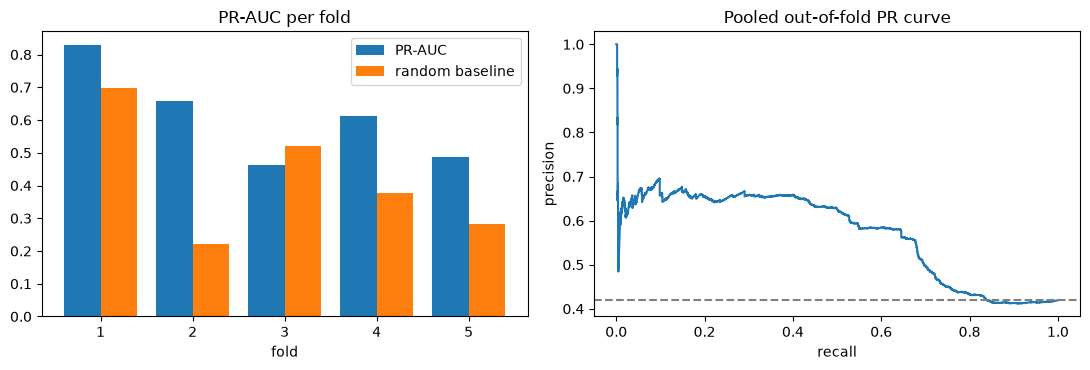

In [7]:
best = res[(res.features == "screens") & (res.model == "random forest")].iloc[0]
best_key = (best["features"], best["model"])
Xb = X_sets[best["features"]].reset_index(drop=True)
print("Best (by mean PR-AUC):", best_key)

fold_df, _ = run_cv(MODELS[best["model"]], Xb, y, groups, gkf)
display(fold_df.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(fold_df.fold - 0.2, fold_df.pr_auc, width=0.4, label="PR-AUC")
ax[0].bar(fold_df.fold + 0.2, fold_df.pos_rate, width=0.4, label="random baseline")
ax[0].set_xlabel("fold"); ax[0].set_title("PR-AUC per fold"); ax[0].legend()

oof = oof_store[best_key]
prec, rec, _ = precision_recall_curve(y, oof)
ax[1].plot(rec, prec)
ax[1].axhline(y.mean(), ls="--", color="grey")
ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].set_title("Pooled out-of-fold PR curve")
plt.tight_layout(); plt.show()

## 6. How much is leakage? Random split vs group split

A random split puts contracts of the same cartel in both train and test, so the model can recognise the cartel instead of the collusion.
The gap below is what you should explain in the report (the methodology paper shows a similar gap: ~91% accuracy on random contracts vs ~77% on random cartels).

In [8]:
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
rand_df, _ = run_cv(MODELS[best["model"]], Xb, y, groups, skf)
cmp = pd.DataFrame({
    "split": ["random (leaky)", "by cartel case"],
    "pr_auc": [rand_df.pr_auc.mean(), fold_df.pr_auc.mean()],
    "pr_auc_std": [rand_df.pr_auc.std(), fold_df.pr_auc.std()],
    "accuracy": [rand_df.accuracy.mean(), fold_df.accuracy.mean()],
    "f1": [rand_df.f1.mean(), fold_df.f1.mean()],
})
display(cmp.round(3))

,split,pr_auc,pr_auc_std,accuracy,f1
0,random (leaky),0.988,0.002,0.948,0.938
1,by cartel case,0.610,0.148,0.660,0.507


## 7. Stress tests

**a) Leave the largest case out.** Largest case = big share of the rows; if the score collapses here, the model leans on that case.
**b) Leave one country out.** Closest to the paper's hardest test. Uses the `screens` set only, since the country dummies would be unseen.

In [9]:
largest = sizes.index[0]
mask = groups == largest
m = MODELS[best["model"]]().fit(Xb.loc[~mask], y[~mask])
p = m.predict_proba(Xb.loc[mask])[:, 1]
print(f"Largest case: {largest} | rows: {mask.sum()} | positive rate: {y[mask].mean():.3f}")
print(f"PR-AUC: {average_precision_score(y[mask], p):.3f}  (random baseline {y[mask].mean():.3f})")
if len(np.unique(y[mask])) == 2:
    print(f"ROC-AUC: {roc_auc_score(y[mask], p):.3f}")

Largest case: country_2_2 | rows: 2779 | positive rate: 0.762
PR-AUC: 0.871  (random baseline 0.762)
ROC-AUC: 0.704


In [10]:
country = df["country"].values
lco_df, _ = run_cv(MODELS[best["model"]], X_sets["screens"], y, country, LeaveOneGroupOut())
lco_df = lco_df.rename(columns={"test_groups": "left_out_country"})
display(lco_df[["left_out_country", "n_test", "pos_rate", "pr_auc", "roc_auc", "accuracy"]].round(3))
print("Mean accuracy leaving a country out:", lco_df.accuracy.mean().round(3),
      "| mean PR-AUC:", lco_df.pr_auc.mean().round(3))

,left_out_country,n_test,pos_rate,pr_auc,roc_auc,accuracy
0,country_1,328,0.570,0.651,0.636,0.534
1,country_2,7860,0.596,0.618,0.517,0.444
2,country_3,1797,0.099,0.210,0.724,0.847
3,country_4,1406,0.472,0.447,0.481,0.489
4,country_5,3308,0.158,0.446,0.825,0.664
5,country_6,162,0.346,0.297,0.430,0.617
6,country_7,755,0.342,0.441,0.443,0.683


Mean accuracy leaving a country out: 0.611 | mean PR-AUC: 0.444


## 8. Per-case view

The task is "collusion period vs other contracts of the same firms", so the number that matters is how well the model separates the two **inside** each cartel (`roc_auc_within_case`).
A case with a very high or very low positive rate can look good or bad for the wrong reasons.

In [11]:
tmp = pd.DataFrame({"case": groups, "y": y, "p": oof_store[best_key]})
case_tbl = tmp.groupby("case").agg(n=("y", "size"), pos_rate=("y", "mean"), mean_pred=("p", "mean"))
within = {c: roc_auc_score(g.y, g.p) for c, g in tmp.groupby("case") if g.y.nunique() == 2}
case_tbl["roc_auc_within_case"] = case_tbl.index.map(within)
display(case_tbl.sort_values("n", ascending=False).head(12).round(3))

,n,pos_rate,mean_pred,roc_auc_within_case
case,,,,
country_2_2,2779,0.762,0.487,0.701
country_5_11,1973,0.048,0.385,0.977
country_2_7,1899,0.524,0.314,0.356
country_2_16,1324,0.415,0.441,0.778
country_3_5,1304,0.062,0.282,0.949
country_2_1,476,0.384,0.676,0.723
country_5_21,461,0.510,0.590,0.602
country_7_1,376,0.604,0.319,0.331
country_2_17,336,0.821,0.583,0.845


## 9. What drives the predictions (exploration only)

Fit on all data **only to look at importances**, never to report performance.
SHAP here is a preview of what the platform will store per contract.

,xgb_importance
lot_bidscount_avg,0.096
benfords_market_yearly_avg,0.094
benfords_market_yearly_avg_lag,0.091
lot_bidscount_avg_lag,0.064
buyer_avg_bidder_yearly_avg_lag,0.057
bid_issubcontracted,0.056
buyer_avg_bidder_yearly,0.047
contract_count_bidder_yearly,0.046
bid_issubcontracted_avg,0.043
benfords_buyer_yearly_avg,0.041


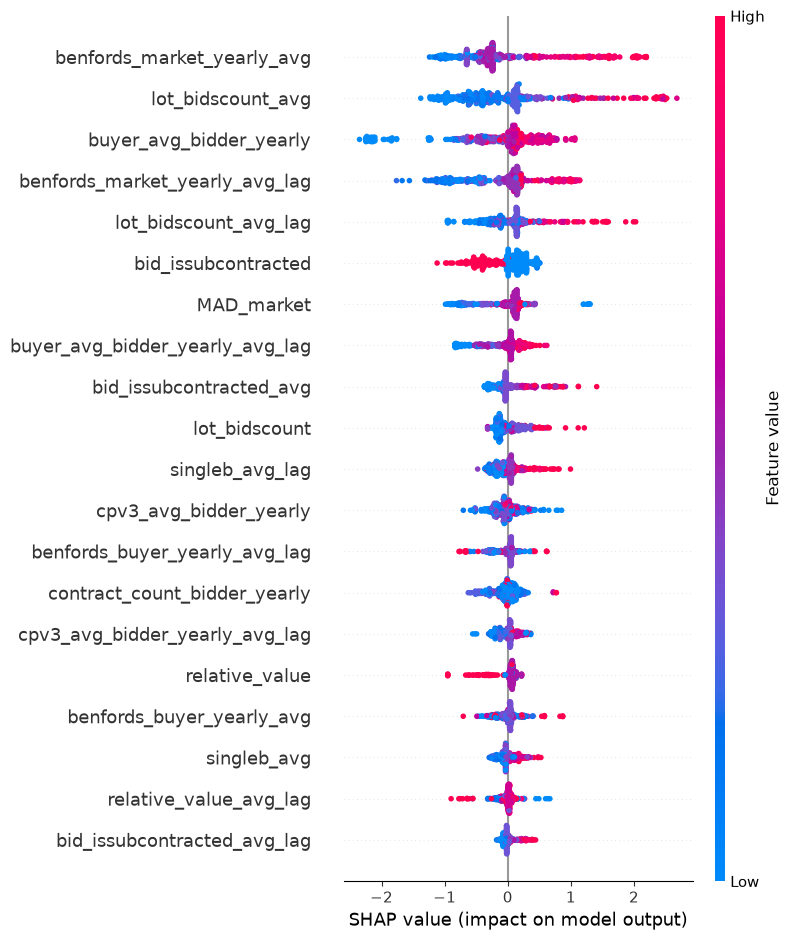

In [12]:
xgb_full = make_xgb().fit(Xb, y)
imp = pd.Series(xgb_full.feature_importances_, index=Xb.columns).sort_values(ascending=False)
display(imp.head(15).round(3).to_frame("xgb_importance"))

try:
    import shap
    sample = Xb.sample(min(500, len(Xb)), random_state=RANDOM_STATE)
    sv = shap.TreeExplainer(xgb_full).shap_values(sample)
    shap.summary_plot(sv, sample, show=True)
except ImportError:
    print("shap not installed: pip install shap")

## 10. Notes to copy into `docs/eda_findings.md`

Fill these in from the outputs above:

- Strongest screens (overall vs case-weighted): ...
- Best model and features: ... PR-AUC mean ± std = ... vs random baseline ...
- Does xgboost/random forest beat logistic regression? By how much? ...
- Random split vs group split gap: ...
- Largest case left out: ...
- Leave-one-country-out (accuracy / PR-AUC): ...
- Does adding `tender_year` or `country`/sector change the picture? (possible proxy effects) ...
- Cases where the model fails and a hypothesis why: ...

## 11. Next steps (hand-off to the backend)

Turn the notebook into plain functions in `ml_pipeline/` (DataFrame in, DataFrame out), so the backend student can wrap them:

- `build_features(df) -> X` (same banned-column rules)
- `make_model()` (the chosen estimator)
- `cross_validate(df) -> DataFrame` (group split by `cartel_id`)
- `fit_final(df) -> model`, saved to `ml_pipeline/artifacts/`
- `score(df, model) -> DataFrame[contract_id, risk_score, top_features]` (SHAP values)

Then add: threshold selection on out-of-fold predictions, SHAP top-10 per contract, and the `score_contracts` command.

In [13]:
print(df.groupby("tender_year")["is_cartel"].agg(["mean", "size"]).round(2))
g = df.groupby(["cartel_id", "is_cartel"])["tender_year"].mean().unstack().dropna()
print("cases with both classes:", len(g), "| share where negatives are later:", (g[0] > g[1]).mean().round(2))

             mean  size
tender_year            
2004         0.69    13
2005         0.88   344
2006         0.63   596
2007         0.55   570
2008         0.60   946
2009         0.73   887
2010         0.72   628
2011         0.81  1049
2012         0.71  1007
2013         0.74   971
2014         0.66  1291
2015         0.36  1608
2016         0.09  1346
2017         0.02  1768
2018         0.00  1393
2019         0.00  1113
2020         0.00    51
2021         0.00    35
cases with both classes: 50 | share where negatives are later: 1.0


In [14]:
# 1) How much does the year alone explain? (same group split)
yr_df, _ = run_cv(make_rf, df[["tender_year"]].astype(float), y, groups, gkf)
print("year only: PR-AUC", yr_df.pr_auc.mean().round(3), "±", yr_df.pr_auc.std().round(3))

# 2) Does the screens model still work among contracts of the SAME year?
tmp = pd.DataFrame({"year": df.tender_year, "y": y, "p": oof_store[("screens", "random forest")]})
rows = [{"year": yr, "n": len(g), "pos_rate": g.y.mean(), "roc_auc": roc_auc_score(g.y, g.p)}
        for yr, g in tmp.groupby("year") if g.y.nunique() == 2 and len(g) >= 50]
yr_tbl = pd.DataFrame(rows); display(yr_tbl.round(3))
print("size-weighted within-year ROC-AUC:", np.average(yr_tbl.roc_auc, weights=yr_tbl.n).round(3))

# 3) Can the screens predict the year? (high R² = they carry time)
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import r2_score
py = cross_val_predict(RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=42),
                       X_sets["screens"], df.tender_year, groups=groups, cv=gkf)
print("R² of tender_year predicted from screens:", round(r2_score(df.tender_year, py), 3))

year only: PR-AUC 0.744 ± 0.214


,year,n,pos_rate,roc_auc
0,2005,344,0.881,0.412
1,2006,596,0.631,0.384
2,2007,570,0.546,0.772
3,2008,946,0.603,0.579
4,2009,887,0.731,0.580
5,2010,628,0.721,0.736
6,2011,1049,0.811,0.775
7,2012,1007,0.709,0.716
8,2013,971,0.745,0.598
9,2014,1291,0.658,0.627


size-weighted within-year ROC-AUC: 0.647
R² of tender_year predicted from screens: 0.171
